In [1]:
import json
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

from ddpm.data.das_dataset import DasDataset

das_data=Path("/datasets/training/earthquake/share/SISSLE_south30")
train_set_earthquake=DasDataset([das_data/"train_1001.h5"])
train_loader_earthquake=DataLoader(train_set_earthquake,batch_size=16,shuffle=False)

print("training windows:",len(train_set_earthquake))

training windows: 16384


In [3]:
from tqdm import tqdm

n=0; s=0.0; s2=0.0; max_abs=0.0; per_std=[]
for batch in tqdm(train_loader_earthquake,desc="Computing statistics"):
    x=batch.double()
    n+=x.numel(); s+=x.sum().item(); s2+=(x**2).sum().item()
    max_abs=max(max_abs,x.abs().max().item())
    per_std.append(x.flatten(1).std(dim=1))

mean=s/n
sigma=(s2/n-mean**2)**0.5
per_std=torch.cat(per_std)
q=torch.quantile(per_std,torch.tensor([0.1,0.5,0.9],dtype=per_std.dtype))

data_scale=0.5/sigma
clip_value=1.03*max_abs*data_scale

print(f"mean: {mean:.5f} | global std: {sigma:.4f} | max abs: {max_abs:.4f}")
print(f"per-window std  10%: {q[0]:.4f} | 50%: {q[1]:.4f} | 90%: {q[2]:.4f}")
print(f"scale factor (global std -> 0.5): {data_scale:.3f}")
print(f"new clip value: {clip_value:.3f}")
print(f"quiet window (10%) std after scaling: {q[0]*data_scale:.3f}")
print(f"alternative factor (median window std -> 0.5): {0.5/q[1]:.3f}")

Computing statistics: 100%|██████████| 1024/1024 [01:41<00:00, 10.07it/s]


mean: -0.00061 | global std: 0.2471 | max abs: 1.1505
per-window std  10%: 0.1281 | 50%: 0.1906 | 90%: 0.3830
scale factor (global std -> 0.5): 2.023
new clip value: 2.397
quiet window (10%) std after scaling: 0.259
alternative factor (median window std -> 0.5): 2.623


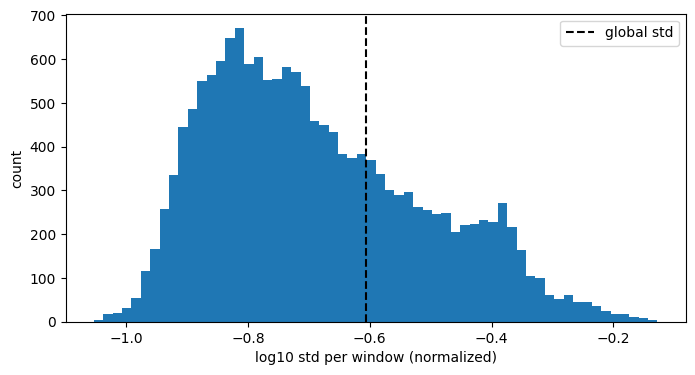

In [4]:
plt.figure(figsize=(8,4))
plt.hist(torch.log10(per_std).numpy(),bins=60)
plt.axvline(torch.log10(torch.tensor(sigma)).item(),color="k",ls="--",label="global std")
plt.xlabel("log10 std per window (normalized)"); plt.ylabel("count"); plt.legend()
plt.show()

In [ ]:
scaling={"sigma_train":sigma,"mean_train":mean,"max_abs_train":max_abs,
         "data_scale":data_scale,"clip_value":clip_value,
         "source":"train_1001.h5, normalized (arcsinh s=50, A_max=12350)"}
Path("checkpoints").mkdir(exist_ok=True)
with open("checkpoints/data_scaling.json","w") as f: json.dump(scaling,f,indent=2)
print(scaling)

{'sigma_train': 0.24713784600538183, 'mean_train': -0.0006101860681798279, 'max_abs_train': 1.1504569053649902, 'data_scale': 2.023162409488313, 'clip_value': 2.397387999610823, 'source': 'train_1001.h5, normalized (arcsinh s=50, A_max=12350)'}


: 